# 0 - The interactive backend, at a glance

`digitalearth`'s **interactive** backend renders pyramids rasters and vector data as live
[HoloViz](https://holoviz.org/) maps (HoloViews + GeoViews + Bokeh, with Datashader and Panel for the
big-data and dashboard layers). Everything is driven by one chainable class, `InteractiveMap`:

```python
InteractiveMap(crs=4326, title="example").field(dem, cmap="terrain").colorbar()
```

Every map below is **live** - pan, zoom, hover and the toolbar are real. **Run this notebook** (Run All /
Shift-Enter) to see them draw.

| Notebook | Covers |
|---|---|
| `01_raster` | `field`, `quadmesh`, `contours`, `rgb`, `large_image`, frozen colour scales |
| `02_big_data` | `rasterize`, `datashade`, `trajectory`, `hexbin` |
| `03_vectors` | `points`, `lines`, `polygons`, `choropleth`, `labels`, vector fields |
| `04_mesh_density` | `trimesh`, `kde` |
| `05_temporal_animation` | `timecube`, `frames`, `play`, `save_animation` |
| `06_decoration_projection` | `tiles`, `features`, `coastlines`, `projection`, `theme` |
| `07_interaction` | `hover`, `on_select`/`on_tap`/`on_reset`/`on_resize`, `draw`, `annotate`, `cross_filter` |
| `08_linked_layouts` | `panels`, `tabs`, `swipe`, `linked_views`, `grid` |
| `09_dashboards_deployment` | `layer_control`, `attribute_table`, `serve`, `share_url`, `live` |

**Setup** - load the backends.


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
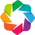

In [1]:
import warnings

warnings.filterwarnings("ignore")  # deliberately silence all warnings to keep the rendered docs clean

import io
from pathlib import Path

import holoviews as hv
import matplotlib.pyplot as plt
from IPython.display import Image

hv.extension("bokeh", "matplotlib")  # Bokeh = interactive (the default); matplotlib only for barbs / projection

# This notebook lives in docs/examples/interactive/guide/, so the bundled sample data at the repo-root
# examples/data/ is four levels up. The kernel's working directory is always the notebook's own folder
# (true for nbval, nbconvert and JupyterLab alike), so one clean relative path is all that is needed.
DATA = Path("../../../../examples/data")

from digitalearth.interactive import InteractiveMap
from pyramids.dataset import Dataset


def show(m, static=False):
    """Return the **live, interactive Bokeh map** - pan, zoom, hover, and the toolbar are all real.

    Run the notebook (Run All / Shift-Enter), or open it in a trusted viewer, to see the maps draw; a saved
    .ipynb only shows them once a kernel executes their JavaScript. A few layers have no Bokeh glyph
    (``projection``, ``streamlines``, wind ``barbs``) and are drawn by matplotlib; for those pass
    ``static=True`` (projected maps switch automatically) to embed a PNG instead.
    """
    if static or getattr(m, "_projection", None) is not None:
        fig = hv.render(m.render(), backend="matplotlib")
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
        plt.close(fig)
        return Image(data=buf.getvalue())
    return m.render()


## Sample data

The guide uses real data bundled at `examples/data/` (acquired with the sibling **earthlens** package):

- **`germany_pop_2020_1km.tif`** / **`..._2010_...`** - gridded population of Germany (persons/km2).
- **`global/ncep_tavg_01..12.tif`** - twelve months of global mean temperature.
- **`heidelberg_birds_2023.geojson`** (3000 points) / **`heidelberg_roads.geojson`** / **`germany_adm1.geojson`**
  (the 16 federal states) - point, line and polygon vector layers.


## A first map

Read the German population raster and draw it as an interactive field. (A `clim` caps the colour at the 99th percentile so the cities do not wash everything else out.)

In [2]:
import numpy as np

pop = Dataset.read_file(str(DATA / "germany_pop_2020_1km.tif"))
values = pop.read_array(band=0)
cap = float(np.nanpercentile(values[values > 0], 99))
print("population raster:", pop.rows, "x", pop.columns, "| EPSG:", pop.epsg, "| p99:", round(cap))

m = InteractiveMap(crs=pop.epsg, title="Germany population 2020 (persons / km2)")
m.field(pop, cmap="inferno", limits=(0.0, cap)).colorbar()
show(m)

population raster: 934 x 1100 | EPSG: 4326 | p99: 1567


:Image   [x,y]   (Band_1)

## One-liner: `quickmap`

`quickmap` picks the builder from the data and returns a ready map; `backend="interactive"` selects this
tier.

In [3]:
from digitalearth import quickmap

m = quickmap(pop, crs=pop.epsg, backend="interactive")
show(m)

:Image   [x,y]   (Band_1)

## Theming

`theme()` sets the Bokeh renderer theme for every layer - `"dark_minimal"`, `"caliber"`, `"night_sky"`,
`"contrast"`, or `None` to restore the default.

In [4]:
m = InteractiveMap(crs=pop.epsg, title="dark theme")
m.theme("dark_minimal").field(pop, cmap="magma", limits=(0.0, cap)).colorbar()
show(m)

:Image   [x,y]   (Band_1)

Open the following notebooks in order, or jump to the capability you need.